# Benchmarking on mouse brain E18.5 samples

In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
dataset = 'E18.5'
path = f'../results/{dataset}/all_results'
adata = sc.read_h5ad(path + '/' + 'adata_all.h5ad')

anno = pd.read_csv(f"../results/{dataset}/anno.csv", index_col=0)
adata.obs =adata.obs.join(anno)
adata.obs['manual-anno']=adata.obs['cluster']

In [3]:
list_Seurat = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
adata.obs['seurat_clusters'] = pd.Categorical(adata.obs['seurat_clusters'],
                                              categories=list_Seurat,
                                              ordered=True)

list_MultiVI = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
adata.obs['MultiVI_clusters'] = pd.Categorical(adata.obs['MultiVI_clusters'],
                                               categories=list_MultiVI,
                                               ordered=True)
list_MOFA = ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14']
adata.obs['MOFA_clusters'] = pd.Categorical(adata.obs['MOFA_clusters'],
                                            categories=list_MOFA,
                                            ordered=True)
list_STAGATE = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
adata.obs['STAGATE_cluster'] = pd.Categorical(adata.obs['STAGATE_cluster'],
                                              categories=list_STAGATE,
                                              ordered=True)
list_GraphST = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
adata.obs['GraphST_cluster'] = pd.Categorical(adata.obs['GraphST_cluster'],
                                              categories=list_GraphST,
                                              ordered=True)
list_COSMOS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
adata.obs['COSMOS_cluster'] = pd.Categorical(adata.obs['COSMOS_cluster'],
                                             categories=list_COSMOS,
                                             ordered=True)

list_PRAGA = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
adata.obs['PRAGA_cluster'] = pd.Categorical(adata.obs['PRAGA_cluster'],
                                            categories=list_PRAGA,
                                            ordered=True)

list_miso = [1, 2,3,4, 5, 6, 7, 8, 9, 10,11, 12,13,14]
adata.obs['miso_cluster'] = pd.Categorical(adata.obs['miso_cluster'],
                                           categories=list_miso,
                                           ordered=True)

list_SpatialGlue = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
adata.obs['SpatialGlue_cluster'] = pd.Categorical(adata.obs['SpatialGlue_cluster'],
                                                  categories=list_SpatialGlue,
                                                  ordered=True)

list_our = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
adata.obs['our_cluster'] = pd.Categorical(adata.obs['our_cluster'],
                                          categories=list_our,
                                          ordered=True)

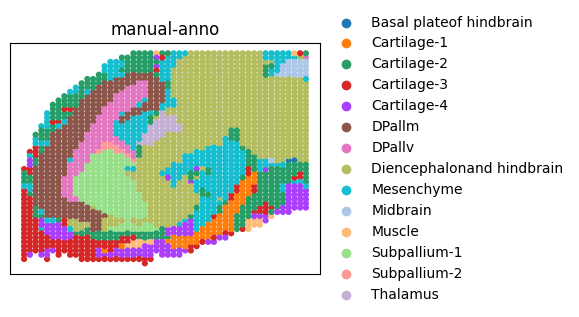

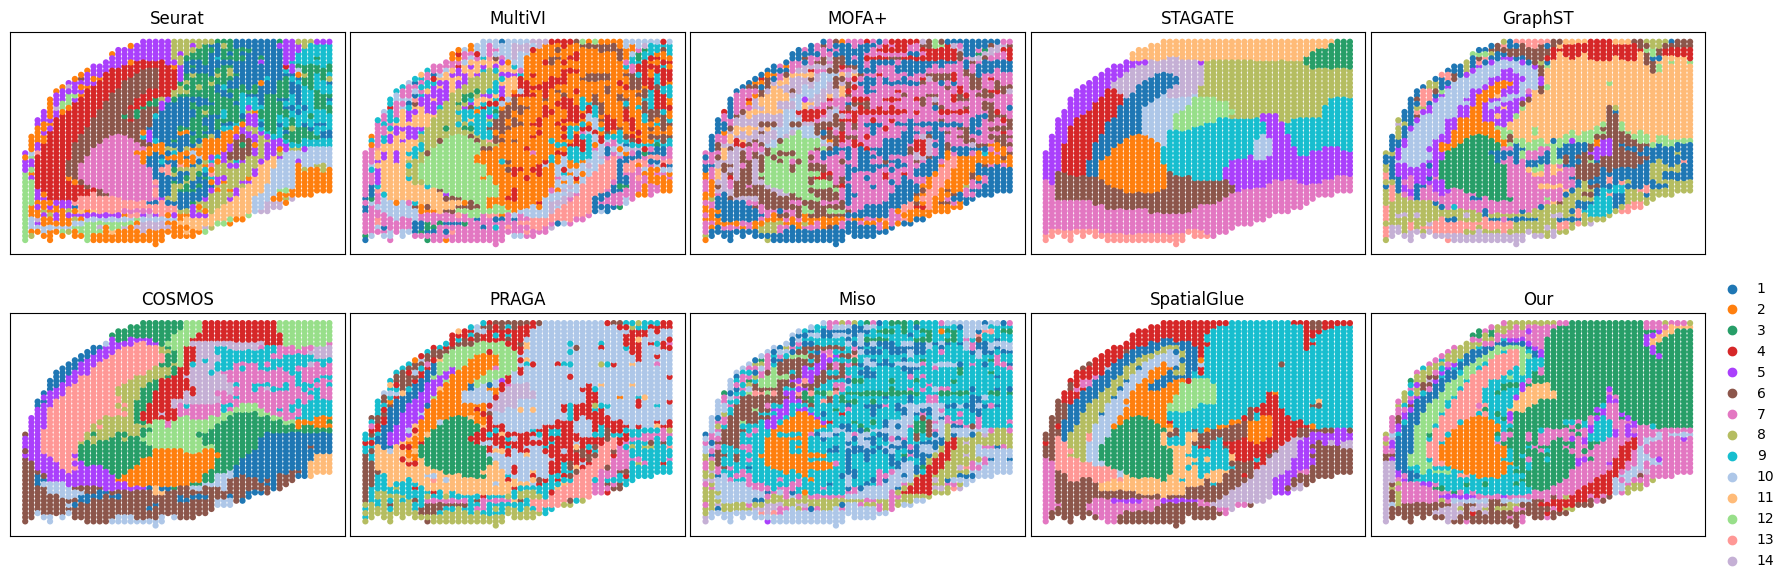

In [4]:
#plt.rcParams['figure.figsize'] = (8,8)
plt.rcParams['font.size'] = 10
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

s_size = 80
#manual_anno3
fig, ax = plt.subplots(figsize=(4, 3))
sc.pl.embedding(adata, basis='spatial', color='manual-anno', title='manual-anno', ax=ax,
                s=s_size, show=False,
                # add_text=True, text_key='manual-anno'
                )
ax.set(xlabel='', ylabel='')

fig, ax_list = plt.subplots(2, 5, figsize=(18, 6))  #(7, 4)
sc.pl.embedding(adata, basis='spatial', color='seurat_clusters', title='Seurat', ax=ax_list[0, 0], s=s_size,
                show=False)
sc.pl.embedding(adata, basis='spatial', color='MultiVI_clusters', title='MultiVI', ax=ax_list[0, 1], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='MOFA_clusters', title='MOFA+', ax=ax_list[0, 2], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='STAGATE_cluster', title='STAGATE', ax=ax_list[0, 3], s=s_size,
                show=False)
sc.pl.embedding(adata, basis='spatial', color='GraphST_cluster', title='GraphST', ax=ax_list[0, 4], s=s_size,
                show=False)
sc.pl.embedding(adata, basis='spatial', color='COSMOS_cluster', title='COSMOS', ax=ax_list[1, 0], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='PRAGA_cluster', title='PRAGA', ax=ax_list[1, 1], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='miso_cluster', title='Miso', ax=ax_list[1, 2], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='SpatialGlue_cluster', title='SpatialGlue', ax=ax_list[1, 3], s=s_size,
                show=False)
sc.pl.embedding(adata, basis='spatial', color='our_cluster', title='Our', ax=ax_list[1, 4], s=s_size, show=False,
                )

# remove legend
ax_list[0, 0].get_legend().remove()
ax_list[0, 1].get_legend().remove()
ax_list[0, 2].get_legend().remove()
ax_list[0, 3].get_legend().remove()
ax_list[0, 4].get_legend().remove()
ax_list[1, 0].get_legend().remove()
ax_list[1, 1].get_legend().remove()
ax_list[1, 2].get_legend().remove()
ax_list[1, 3].get_legend().remove()
# ax_list[1, 4].get_legend().remove()

# remove x, y axis
ax_list[0, 0].set_xlabel('')
ax_list[0, 1].set_xlabel('')
ax_list[0, 2].set_xlabel('')
ax_list[0, 3].set_xlabel('')
ax_list[0, 4].set_xlabel('')

ax_list[1, 0].set_xlabel('')
ax_list[1, 1].set_xlabel('')
ax_list[1, 2].set_xlabel('')
ax_list[1, 3].set_xlabel('')
ax_list[1, 4].set_xlabel('')

ax_list[0, 0].set_ylabel('')
ax_list[0, 1].set_ylabel('')
ax_list[0, 2].set_ylabel('')
ax_list[0, 3].set_ylabel('')
ax_list[0, 4].set_ylabel('')

ax_list[1, 0].set_ylabel('')
ax_list[1, 1].set_ylabel('')
ax_list[1, 2].set_ylabel('')
ax_list[1, 3].set_ylabel('')
ax_list[1, 4].set_ylabel('')

plt.tight_layout(w_pad=0.4)


In [5]:
def clustering_accuracy(y_true, y_pred):
    from scipy.optimize import linear_sum_assignment
    from sklearn.metrics import accuracy_score
    import numpy as np

    y_true = np.array(y_true, dtype=int)
    y_pred = np.array(y_pred, dtype=int)
    D = max(y_pred.max(), y_true.max()) + 1
    w = np.zeros((D, D), dtype=np.int64)
    for i in range(y_pred.size):
        w[y_pred[i], y_true[i]] += 1
    row_ind, col_ind = linear_sum_assignment(w.max() - w)
    y_pred_aligned = np.array([col_ind[label] for label in y_pred])
    return accuracy_score(y_true, y_pred_aligned)


In [6]:
import pandas as pd
from sklearn.metrics import (
    normalized_mutual_info_score, mutual_info_score, adjusted_mutual_info_score,
    v_measure_score, homogeneity_score, completeness_score,
    adjusted_rand_score, fowlkes_mallows_score
)

list_domain_names = [
    'seurat_clusters', 'MultiVI_clusters', 'MOFA_clusters',
    'GraphST_cluster', 'STAGATE_cluster', 'COSMOS_cluster', 'PRAGA_cluster',
    'miso_cluster', 'SpatialGlue_cluster',
    'our_cluster'
]

results = {}

for domain in list_domain_names:
    print(f"\n{domain} :")

    true_labels = adata.obs['manual-anno'].astype('category').cat.codes
    pred_labels = adata.obs[domain].astype('category').cat.codes

    metrics = {
        "Acc": clustering_accuracy(true_labels, pred_labels),
        # "Mutual_Info": mutual_info_score(true_labels, pred_labels),
        "V-measure": v_measure_score(true_labels, pred_labels),
        "Homogeneity": homogeneity_score(true_labels, pred_labels),
        "Completeness": completeness_score(true_labels, pred_labels),
        "NMI": normalized_mutual_info_score(true_labels, pred_labels,average_method="geometric"),
        "AMI": adjusted_mutual_info_score(true_labels, pred_labels),
        "FMI": fowlkes_mallows_score(true_labels, pred_labels),
        "ARI": adjusted_rand_score(true_labels, pred_labels),
    }

    for k, v in metrics.items():
        print(f"{k:<15}: {v:.10f}")

    results[domain] = metrics


df_results = pd.DataFrame(results).T



seurat_clusters :
Acc            : 0.5576279292
V-measure      : 0.5988994264
Homogeneity    : 0.6541676204
Completeness   : 0.5522425069
NMI            : 0.6010483896
AMI            : 0.5915799888
FMI            : 0.4827389582
ARI            : 0.3914612433

MultiVI_clusters :
Acc            : 0.5198469632
V-measure      : 0.5338184514
Homogeneity    : 0.5699219563
Completeness   : 0.5020166241
NMI            : 0.5348927897
AMI            : 0.5251523273
FMI            : 0.4650997262
ARI            : 0.3734100624

MOFA_clusters :
Acc            : 0.4112864658
V-measure      : 0.3749028195
Homogeneity    : 0.3653609309
Completeness   : 0.3849564718
NMI            : 0.3750307386
AMI            : 0.3641705222
FMI            : 0.3364730729
ARI            : 0.2027671428

GraphST_cluster :
Acc            : 0.5279770445
V-measure      : 0.5222393224
Homogeneity    : 0.5594550684
Completeness   : 0.4896660415
NMI            : 0.5233986519
AMI            : 0.5133693679
FMI            : 0.500385

Text(0, 0.5, 'Value')

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

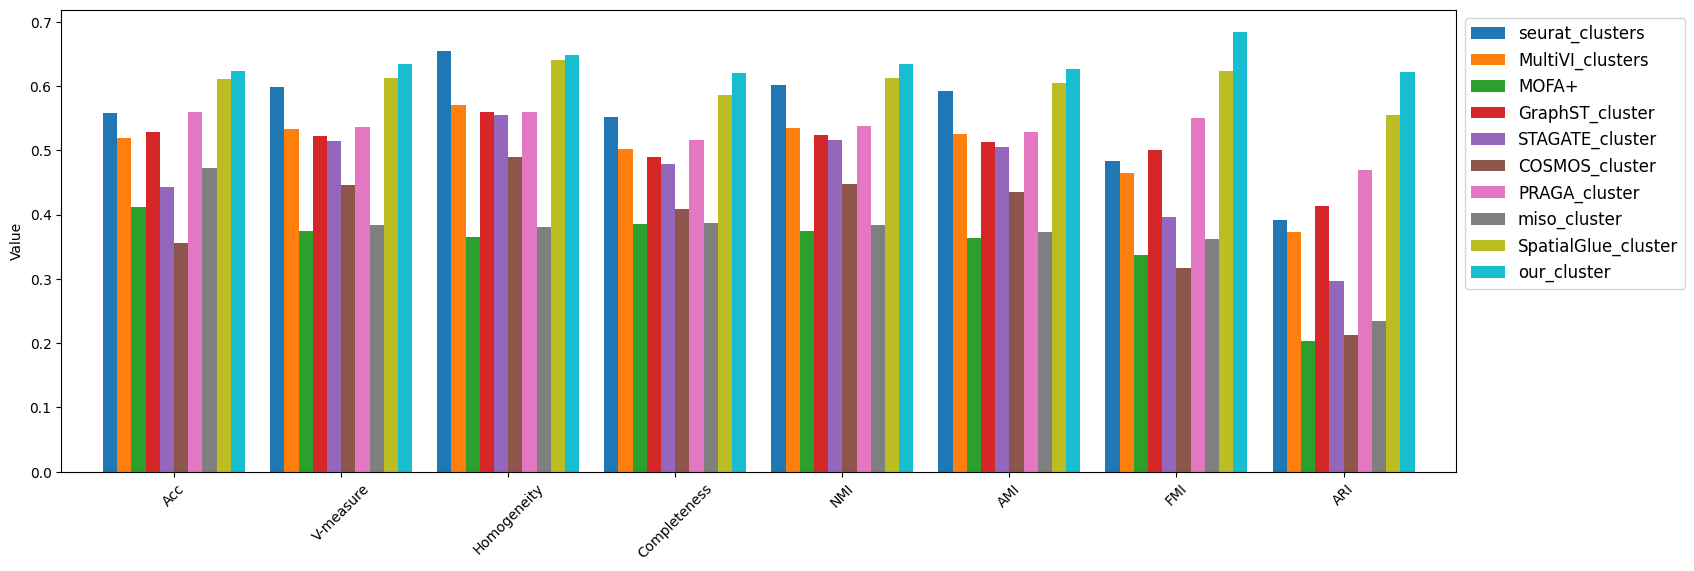

In [7]:
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.figsize'] = (18, 6)


# 直接使用上一单元计算得到的 DataFrame，无需先保存再读取 CSV
res = df_results.rename(index={'MOFA_clusters': 'MOFA+'}).copy()

res.T.plot(kind='bar', width=0.85)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=12)
plt.xticks(rotation=45)
plt.ylabel('Value')

